In [ ]:
# path setup (scripts/nb_layout.py): run from the folder this notebook belongs to, with scripts/ importable
import os, sys
if '_HHS_ROOT' not in globals():
    _d = os.getcwd()
    while os.path.basename(_d) != 'notebooks' and os.path.dirname(_d) != _d:
        _d = os.path.dirname(_d)
    _HHS_ROOT = os.path.dirname(_d) if os.path.basename(_d) == 'notebooks' else os.getcwd()
    os.chdir(os.path.join(_HHS_ROOT, '.'))
    sys.path[:0] = [os.path.join(_HHS_ROOT, 'scripts'), os.getcwd()]

# PRR decomposition without background traffic (campaign v3, 0 cars)

**Data:** `out/remote_v3`, 0 background cars, 3 scenarios × 2 traffic classes × 10 seeds per arm. Without
background vehicles a lost (TB, member) pair is due to the channel (path loss, building and vehicle blockage,
fading) and decoding only.

**Arms:** R1 blind leader (3 copies, decoded independently); R1_bsc the same with blind soft combining; R3 leader
HARQ Option 2; **R4_bsc = "Blind + C"**: Kuo helper relaying blindly in the handed slots, receivers combining every
copy; R4.2 Kuo helper with Option 2 and **no** takeover; **R6** Kuo helper + Option 2 + takeover. R6 − R4.2 is
the takeover **package**, not one rule: besides the takeover and fallback, R6's helper suppresses its own ACK and
listens, R4.2's helper ACKs like any member and cannot hear the others in that feedback occasion. The listening
difference changes the relay cost (R4.2 sends redundant helper copies), not the delivery (section 5b: TBs whose
helper received the first copy are delivered alike).

**Attribution.** Each delivered pair is attributed to the copy that **completed** its decode: `L1` the leader's
first transmission, `Lrep` a later leader copy in its own slot (HARQ retransmission in R3, blind repetition in R1),
`H` a helper copy, `T1` a leader takeover after a helper NACK, `T2` a leader takeover by the fallback (no helper SCI
in the handed slot), `LH` leader and helper in the same slot both decoded (rare). `lost` = not delivered by the PDB.
The shares add up to the PRR (plus `lost` = 1), and the differences between two arms add up to their PRR difference
exactly. **Not counterfactual:** a copy may complete a decode by combining with earlier failed copies, and a
member decoded by one copy might have been reached by a later one; and a takeover can also act **indirectly** (the
helper decodes the leader's takeover copy and then relays it, which is attributed to `H`). The causal effect of an
arm is the paired PRR difference (same traces, seeds and packets; section 2).

**Pairing.** Inside each family (leader only: R1, R1_bsc, R3; helper: R4_bsc, R4.2, R6) every run has identical
packets, and periodic traffic is identical across all arms. Under **aperiodic** traffic the packet arrivals differ
between the two families (known, `paper_notes/round3/CHECKS.md`): R6 vs R3 / R1 / R1_bsc is then paired by seed and
mobility trace but not packet by packet, and each arm's shares use its own pair count. R6 vs R4.2 and R6 vs R4_bsc
are paired packet by packet everywhere.

**Statistics:** seeds are the resampling unit (10 per cell); 95 % percentile bootstrap, paired comparisons resample
the same seed indices in both arms (20 000 replicates, fixed RNG). Binned points need ≥ 5 seeds and ≥ 200 pairs.


In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display, Markdown
sys.path.insert(0, os.path.abspath('.'))
import nobg_decomposition as N        # collector (reads out/remote_v3, caches out/cache_nobg_v3)
import takeover_audit as A            # bootstrap, grid and style helpers
pd.set_option('display.width', 230); pd.set_option('display.max_columns', 40)
FIG = os.path.join(os.path.abspath('.'), 'figures', 'nobg_v3'); os.makedirs(FIG, exist_ok=True)
F = lambda n: os.path.join(FIG, n)
ARMS = ['R1', 'R1_bsc', 'R3', 'R4_bsc', 'R4.2', 'R6']
D = N.collect(ARMS); CAT, WIN, RUN = D['cat'], D['win'], D['run']
A.LABEL |= {'R1_bsc': 'R1_bsc leader blind + C', 'R4_bsc': 'R4_bsc Kuo blind + C (Blind+C)'}
A.STYLE |= {'R1_bsc': ('dimgray', '-.', 1.5), 'R4_bsc': ('tab:purple', '-', 2.0)}
A.MARK |= {'R1_bsc': 'o', 'R4_bsc': 's'}
SRC = ['L1', 'Lrep', 'H', 'T1', 'T2', 'LH', 'lost']
SRC_NAME = {'L1': 'leader 1st copy', 'Lrep': 'leader retx / repetition', 'H': 'helper copy',
            'T1': 'takeover: helper NACK', 'T2': 'takeover: fallback', 'LH': 'leader+helper same slot', 'lost': 'lost'}
SRC_COL = {'L1': '#9e9e9e', 'Lrep': '#4d4d4d', 'H': '#6a3d9a', 'T1': '#1b9e77', 'T2': '#a6dba0', 'LH': '#e6ab02',
           'lost': '#ffffff'}
CELLS = [(sc, tr) for tr in A.TRS for sc in A.SCS]
# completeness: every arm 3 x 2 x 10 runs, one cat/win/run entry per run, identical pairs per run across arms
exp = pd.MultiIndex.from_product([ARMS, A.SCS, A.TRS, range(1, 11)], names=['arm', 'sc', 'tr', 'seed'])
got = pd.MultiIndex.from_frame(RUN[['arm', 'sc', 'tr', 'seed']])
assert got.is_unique and len(exp.difference(got)) == 0 and len(got.difference(exp)) == 0, 'run set incomplete'
pp = RUN.pivot_table(index=['sc', 'tr', 'seed'], columns='arm', values='n_pairs')
FAM = {'leader': ['R1', 'R1_bsc', 'R3'], 'helper': ['R4_bsc', 'R4.2', 'R6']}
for f, arms in FAM.items():   # within a family the packets are identical in every run
    assert (pp[arms].nunique(axis=1) == 1).all(), f'pair counts differ inside the {f} family'
per = pp.xs('periodic1tb', level='tr')
assert (per.nunique(axis=1) == 1).all(), 'periodic: pair counts differ across families'
ap = pp.xs('aperiodic1tb', level='tr')
n_ap = int((ap.nunique(axis=1) > 1).sum())
_c = CAT.groupby(['arm', 'sc', 'tr', 'seed']).n.sum(); _r = RUN.set_index(['arm', 'sc', 'tr', 'seed']).n_pairs
assert len(_c) == len(_r) and (_c - _r.reindex(_c.index)).abs().max() == 0, 'category counts do not add up to the pairs'
print(f'{len(RUN)} runs = {len(ARMS)} arms x 60. Packets identical inside each family in every run and across '
      f'families for periodic traffic; aperiodic: {n_ap} of {len(ap)} runs differ between the leader-only and the '
      f'helper family (known: aperiodic arrivals are not paired across families, paper_notes/round3/CHECKS.md). '
      f'Late decodes (after the PDB): {int(RUN.n_late.sum())}')


360 runs = 6 arms x 60. Packets identical inside each family in every run and across families for periodic traffic; aperiodic: 30 of 30 runs differ between the leader-only and the helper family (known: aperiodic arrivals are not paired across families, paper_notes/round3/CHECKS.md). Late decodes (after the PDB): 0


## 1. PRR and its decomposition by delivering copy
Bars: share of all (TB, member) pairs by the copy that completed the decode; the top of the coloured part is the
PRR (white = lost). Table: PRR with seed CI.

arm                    R1  R1_bsc      R3  R4_bsc    R4.2      R6
sc   tr                                                          
hwy  aperiodic1tb  0.9682  0.9749  0.9798  0.9668  0.9682  0.9937
     periodic1tb   0.9833  0.9885  0.9918  0.9819  0.9816  0.9981
rbt  aperiodic1tb  0.6042  0.6366  0.6367  0.7560  0.7531  0.8013
     periodic1tb   0.6270  0.6700  0.6780  0.8371  0.8431  0.8564
rbtE aperiodic1tb  0.6687  0.7004  0.7026  0.8561  0.8496  0.8886
     periodic1tb   0.6934  0.7328  0.7532  0.8981  0.8966  0.9203

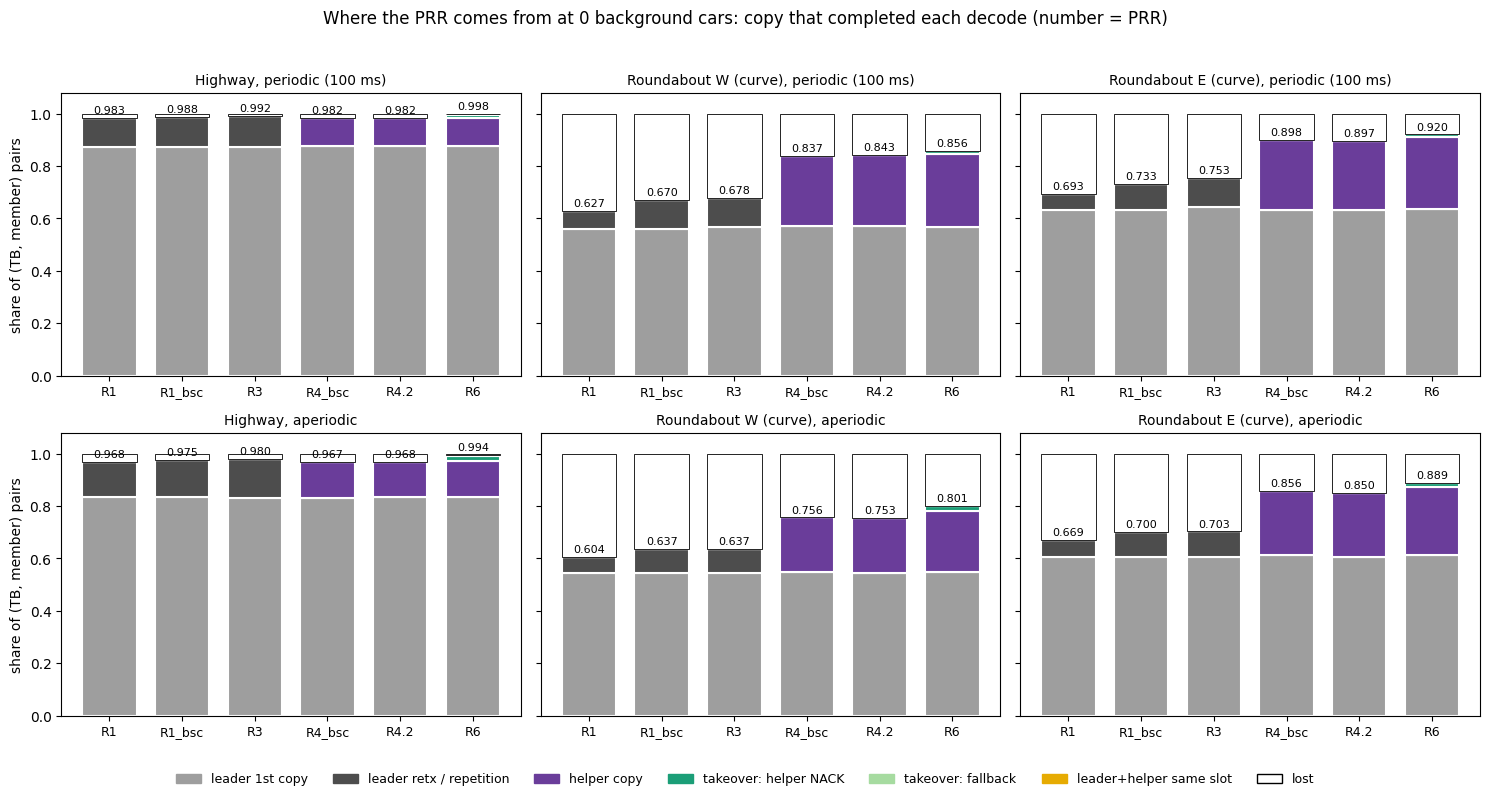

src                          L1   Lrep      H    T1    T2   LH   lost
sc   tr           arm                                                
hwy  aperiodic1tb R1      83.44  13.38   0.00  0.00  0.00  0.0   3.18
                  R1_bsc  83.44  14.05   0.00  0.00  0.00  0.0   2.51
                  R3      83.00  14.98   0.00  0.00  0.00  0.0   2.02
                  R4.2    83.34   0.00  13.48  0.00  0.00  0.0   3.18
                  R4_bsc  83.15   0.00  13.53  0.00  0.00  0.0   3.32
                  R6      83.28   0.00  13.70  2.11  0.28  0.0   0.63
     periodic1tb  R1      87.31  11.03   0.00  0.00  0.00  0.0   1.67
                  R1_bsc  87.32  11.52   0.00  0.00  0.00  0.0   1.15
                  R3      87.19  11.99   0.00  0.00  0.00  0.0   0.82
                  R4.2    87.53   0.00  10.64  0.00  0.00  0.0   1.84
                  R4_bsc  87.45   0.00  10.74  0.00  0.00  0.0   1.81
                  R6      87.52   0.00  10.86  1.20  0.24  0.0   0.19
rbt  aperiodic1tb R1      54.33   6.09   0.00  0.00  0.00  0.0  39.58
                  R1_bsc  54.28   9.38   0.00  0.00  0.00  0.0  36.34
                  R3      54.21   9.46   0.00  0.00  0.00  0.0  36.33
                  R4.2    54.30   0.00  21.01  0.00  0.00  0.0  24.69
                  R4_bsc  54.83   0.00  20.77  0.00  0.00  0.0  24.40
                  R6      54.78   0.00  23.36  1.88  0.11  0.0  19.87
     periodic1tb  R1      56.09   6.61   0.00  0.00  0.00  0.0  37.30
                  R1_bsc  56.09  10.91   0.00  0.00  0.00  0.0  33.00
                  R3      56.88  10.92   0.00  0.00  0.00  0.0  32.20
                  R4.2    57.26   0.00  27.05  0.00  0.00  0.0  15.69
                  R4_bsc  56.90   0.00  26.81  0.00  0.00  0.0  16.29
                  R6      56.82   0.00  27.65  1.11  0.06  0.0  14.36
rbtE aperiodic1tb R1      60.59   6.28   0.00  0.00  0.00  0.0  33.13
                  R1_bsc  60.55   9.49   0.00  0.00  0.00  0.0  29.96
                  R3      60.58   9.68   0.00  0.00  0.00  0.0  29.74
                  R4.2    60.43   0.00  24.53  0.00  0.00  0.0  15.04
                  R4_bsc  61.17   0.00  24.43  0.00  0.00  0.0  14.39
                  R6      61.27   0.00  25.95  1.60  0.05  0.0  11.14
     periodic1tb  R1      63.35   5.99   0.00  0.00  0.00  0.0  30.66
                  R1_bsc  63.36   9.92   0.00  0.00  0.00  0.0  26.72
                  R3      64.21  11.10   0.00  0.00  0.00  0.0  24.68
                  R4.2    63.20   0.00  26.45  0.00  0.00  0.0  10.34
                  R4_bsc  63.23   0.00  26.58  0.00  0.00  0.0  10.19
                  R6      63.39   0.00  27.57  1.04  0.02  0.0   7.97

In [2]:
def shares(arms=ARMS):
    t = CAT[CAT.arm.isin(arms)].groupby(['sc', 'tr', 'arm', 'src']).n.sum().unstack('src').reindex(columns=SRC, fill_value=0).fillna(0)
    return t.div(t.sum(1), axis=0)
SH = shares(); SH.to_csv(F('tab_decomposition_shares.csv'))
rows = []
for (sc, tr, arm), g in WIN.groupby(['sc', 'tr', 'arm']):
    r, lo, hi, n = A.boot_ratio(g, 'n_deliv', 'n_pairs')
    rows.append(dict(sc=sc, tr=tr, arm=arm, prr=r, lo=lo, hi=hi, n_seeds=n))
PRR = pd.DataFrame(rows); PRR.to_csv(F('tab_prr.csv'), index=False)
display(PRR.pivot_table(index=['sc', 'tr'], columns='arm', values='prr')[ARMS].round(4))

fig, ax = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for i, tr in enumerate(A.TRS):
    for j, sc in enumerate(A.SCS):
        a = ax[i, j]; bottom = np.zeros(len(ARMS))
        for s in SRC:
            v = SH.loc[(sc, tr)].reindex(ARMS)[s].values
            a.bar(range(len(ARMS)), v, bottom=bottom, color=SRC_COL[s], edgecolor='k' if s == 'lost' else 'white',
                  lw=.6 if s == 'lost' else 1.5, width=.75)
            bottom += v
        prr = 1 - SH.loc[(sc, tr)].reindex(ARMS).lost.values
        for x, p in enumerate(prr):
            a.text(x, p + .01, f'{p:.3f}', ha='center', va='bottom', fontsize=8)
        a.set_xticks(range(len(ARMS))); a.set_xticklabels(ARMS, fontsize=9)
        a.set_title(f'{A.SCN[sc]}, {A.TRN[tr]}', fontsize=10); a.set_ylim(0, 1.08)
        if j == 0: a.set_ylabel('share of (TB, member) pairs')
fig.suptitle('Where the PRR comes from at 0 background cars: copy that completed each decode (number = PRR)', fontsize=12)
fig.legend(handles=[Patch(facecolor=SRC_COL[s], edgecolor='k' if s == 'lost' else SRC_COL[s], label=SRC_NAME[s]) for s in SRC],
           loc='lower center', ncol=7, fontsize=9, frameon=False)
fig.tight_layout(rect=(0, .05, 1, .96)); fig.savefig(F('fig1_decomposition.pdf'), bbox_inches='tight')
fig.savefig(F('fig1_decomposition.png'), dpi=130, bbox_inches='tight'); plt.show()
display((SH * 100).round(2))


## 2. Paired gain of R6 and its decomposition
For each comparison R6 − X the PRR gain (same seeds, packets and traces) is split into the change of each
delivering-copy share; the parts add up to the gain exactly (`lost` change = − gain). Intervals: paired bootstrap of
each part with the same seed indices. Reading it:
- `L1` ≈ 0 everywhere: the first copy is the same in every arm (a check of the pairing, not a gain);
- vs **R3**: the leader's retransmissions (`Lrep`, negative) are replaced by helper copies and takeovers;
- vs **R4_bsc (Blind + C)**: same helper selection, blind relaying with combining vs feedback-driven relaying with
  takeover;
- vs **R4.2**: the takeover package (in R6 the named helper also never ACKs and listens to the other members' feedback, so it can cancel redundant relays; in R4.2 it ACKs like any member and, being half duplex, cannot hear the others in that feedback occasion; `platoon_harq_robustness_eval.cc`, ACK suppression installed only for Option 2 with `helperTakeover`). The delivery difference comes from the takeover (section 5b). Its **direct** part is `T1 + T2` (leader takeover copies that
  completed a decode); the change of `H` is its **indirect** part (the helper decodes the leader's takeover copy and
  relays, or relays to members the takeover did not reach), plus chance;
- vs **R1**: everything beyond the blind leader.
Gains are given as absolute (pp), relative (%) and loss reduction (%).

**Paired PRR gain of R6** (abs in pp with 95 % CI; rel %; loss reduction %; seeds where R6 is better)

n_seeds  packet_paired  prr_p  prr_b  abs_pp  abs_lo  abs_hi  rel_pct  loss_red_pct  seeds_better
baseline sc   tr                                                                                                             
R3       hwy  periodic1tb        10           True  0.998  0.992   0.636   0.289   1.054    0.642        77.370            10
         rbt  periodic1tb        10           True  0.856  0.678  17.842  16.907  18.692   26.317        55.408            10
         rbtE periodic1tb        10           True  0.920  0.753  16.712  16.029  17.343   22.190        67.703            10
         hwy  aperiodic1tb       10          False  0.994  0.980   1.386   0.855   2.029    1.414        68.635            10
         rbt  aperiodic1tb       10          False  0.801  0.637  16.452  15.085  17.676   25.839        45.290            10
         rbtE aperiodic1tb       10          False  0.889  0.703  18.607  17.624  19.591   26.485        62.562            10
R4_bsc   hwy  periodic1tb        10           True  0.998  0.982   1.622   1.014   2.331    1.652        89.708            10
         rbt  periodic1tb        10           True  0.856  0.837   1.933   1.144   2.727    2.309        11.864             9
         rbtE periodic1tb        10           True  0.920  0.898   2.218   1.488   2.847    2.470        21.768             9
         hwy  aperiodic1tb       10           True  0.994  0.967   2.686   1.797   3.688    2.779        80.924            10
         rbt  aperiodic1tb       10           True  0.801  0.756   4.528   2.779   6.107    5.989        18.554             8
         rbtE aperiodic1tb       10           True  0.889  0.856   3.258   1.890   4.492    3.806        22.636             9
R4.2     hwy  periodic1tb        10           True  0.998  0.982   1.652   1.212   2.188    1.683        89.877            10
         rbt  periodic1tb        10           True  0.856  0.843   1.334   0.570   2.216    1.583         8.503             9
         rbtE periodic1tb        10           True  0.920  0.897   2.372   1.262   3.401    2.646        22.934             8
         hwy  aperiodic1tb       10           True  0.994  0.968   2.548   1.878   3.321    2.632        80.095            10
         rbt  aperiodic1tb       10           True  0.801  0.753   4.817   3.537   5.961    6.396        19.508            10
         rbtE aperiodic1tb       10           True  0.889  0.850   3.909   2.987   4.862    4.601        25.983            10
R1       hwy  periodic1tb        10           True  0.998  0.983   1.481   0.971   2.060    1.507        88.839            10
         rbt  periodic1tb        10           True  0.856  0.627  22.940  21.909  24.003   36.586        61.502            10
         rbtE periodic1tb        10           True  0.920  0.693  22.691  21.701  23.697   32.725        74.000            10
         hwy  aperiodic1tb       10          False  0.994  0.968   2.544   1.897   3.298    2.627        80.068            10
         rbt  aperiodic1tb       10          False  0.801  0.604  19.701  18.111  21.039   32.603        49.780            10
         rbtE aperiodic1tb       10          False  0.889  0.669  21.990  21.201  22.703   32.883        66.385            10

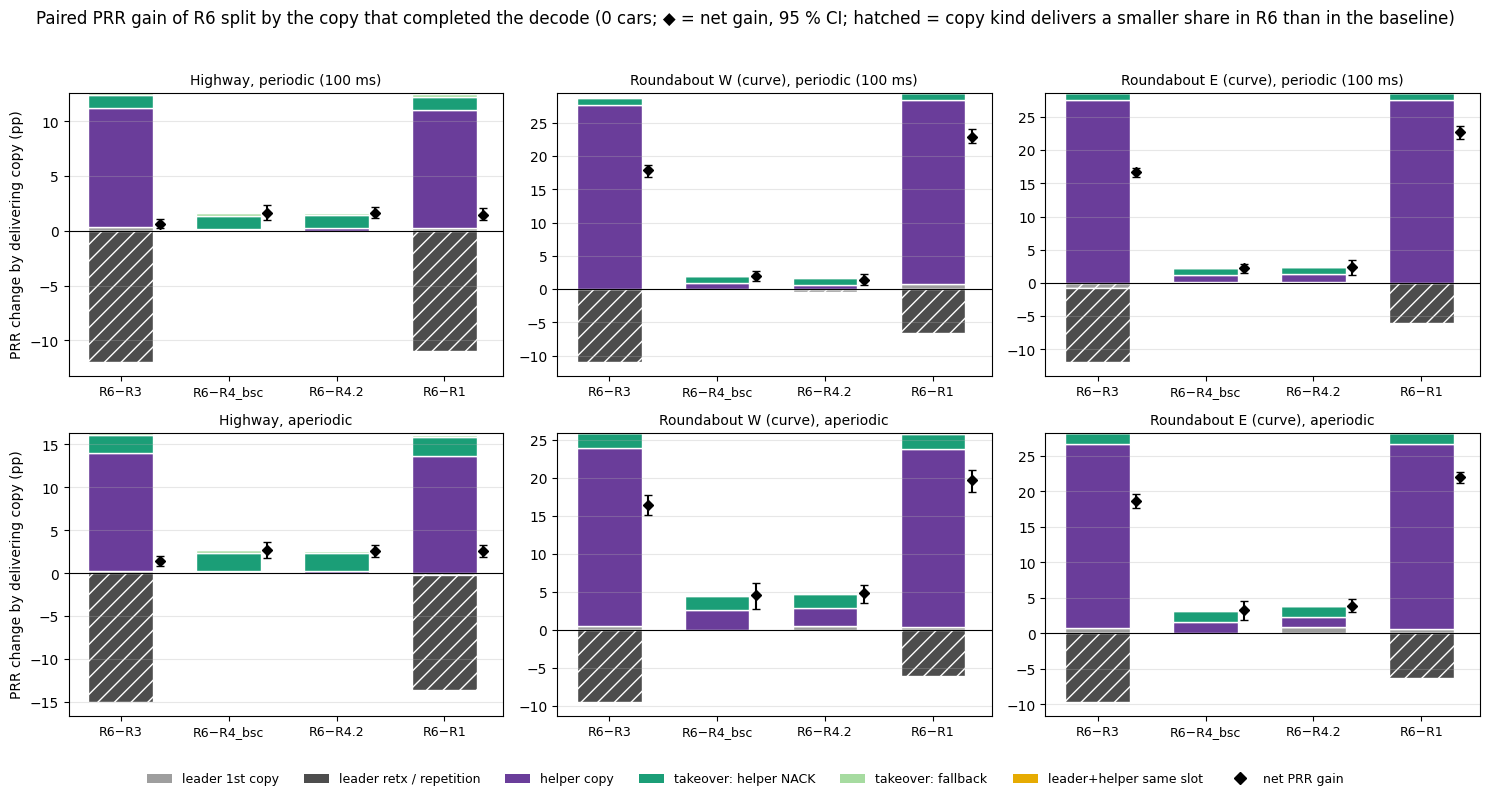

src                           L1   Lrep      H    T1    T2   LH   lost
baseline sc   tr                                                      
R1       hwy  aperiodic1tb -0.16 -13.38  13.70  2.11  0.28  0.0  -2.54
              periodic1tb   0.21 -11.03  10.86  1.20  0.24  0.0  -1.48
         rbt  aperiodic1tb  0.44  -6.09  23.36  1.88  0.11  0.0 -19.70
              periodic1tb   0.73  -6.61  27.65  1.11  0.06  0.0 -22.94
         rbtE aperiodic1tb  0.68  -6.28  25.95  1.60  0.05  0.0 -21.99
              periodic1tb   0.04  -5.99  27.57  1.04  0.02  0.0 -22.69
R3       hwy  aperiodic1tb  0.28 -14.98  13.70  2.11  0.28  0.0  -1.39
              periodic1tb   0.33 -11.99  10.86  1.20  0.24  0.0  -0.64
         rbt  aperiodic1tb  0.56  -9.46  23.36  1.88  0.11  0.0 -16.45
              periodic1tb  -0.06 -10.92  27.65  1.11  0.06  0.0 -17.84
         rbtE aperiodic1tb  0.69  -9.68  25.95  1.60  0.05  0.0 -18.61
              periodic1tb  -0.82 -11.10  27.57  1.04  0.02  0.0 -16.71
R4.2     hwy  aperiodic1tb -0.06   0.00   0.22  2.11  0.28  0.0  -2.55
              periodic1tb  -0.01   0.00   0.22  1.20  0.24  0.0  -1.65
         rbt  aperiodic1tb  0.48   0.00   2.35  1.88  0.11  0.0  -4.82
              periodic1tb  -0.44   0.00   0.60  1.11  0.06  0.0  -1.33
         rbtE aperiodic1tb  0.84   0.00   1.42  1.60  0.05  0.0  -3.91
              periodic1tb   0.19   0.00   1.11  1.04  0.02  0.0  -2.37
R4_bsc   hwy  aperiodic1tb  0.13   0.00   0.17  2.11  0.28  0.0  -2.69
              periodic1tb   0.07   0.00   0.12  1.20  0.24  0.0  -1.62
         rbt  aperiodic1tb -0.05   0.00   2.60  1.88  0.11  0.0  -4.53
              periodic1tb  -0.08   0.00   0.85  1.11  0.06  0.0  -1.93
         rbtE aperiodic1tb  0.09   0.00   1.52  1.60  0.05  0.0  -3.26
              periodic1tb   0.16   0.00   0.99  1.04  0.02  0.0  -2.22

In [3]:
rng = np.random.default_rng(A.RNG_SEED)
def seed_counts(arm, sc, tr):
    c = CAT[(CAT.arm == arm) & (CAT.sc == sc) & (CAT.tr == tr)].pivot_table(index='seed', columns='src', values='n',
                                                                            aggfunc='sum', fill_value=0)
    return c.reindex(columns=SRC, fill_value=0).reindex(range(1, 11), fill_value=0).sort_index()
def paired_parts(p, b, sc, tr, B=A.B_PAIRED):
    cp, cb = seed_counts(p, sc, tr), seed_counts(b, sc, tr)
    assert (cp.index == cb.index).all()
    same_pkts = bool((cp.sum(1) == cb.sum(1)).all())
    npv, nbv = cp.sum(1).to_numpy(float), cb.sum(1).to_numpy(float)    # each arm's own pair count per seed
    P, Bm = cp.to_numpy(float), cb.to_numpy(float)
    idx = rng.integers(0, len(npv), (B, len(npv)))                    # same seed indices for both arms
    diff = (P[idx].sum(1) / npv[idx].sum(1)[:, None] - Bm[idx].sum(1) / nbv[idx].sum(1)[:, None]) * 100
    point = (P.sum(0) / npv.sum() - Bm.sum(0) / nbv.sum()) * 100
    lo, hi = np.percentile(diff, [2.5, 97.5], axis=0)
    out = pd.DataFrame(dict(src=SRC, pp=point, lo=lo, hi=hi))
    pb, pbase = 1 - P[:, -1].sum() / npv.sum(), 1 - Bm[:, -1].sum() / nbv.sum()
    gain_bs = -diff[:, -1]
    seeds_better = int(((1 - P[:, -1] / npv) - (1 - Bm[:, -1] / nbv) > 0).sum())
    tot = dict(prr_p=pb, prr_b=pbase, abs_pp=100 * (pb - pbase), abs_lo=np.percentile(gain_bs, 2.5),
               abs_hi=np.percentile(gain_bs, 97.5), rel_pct=100 * (pb / pbase - 1),
               loss_red_pct=100 * (pb - pbase) / (1 - pbase), seeds_better=seeds_better, n_seeds=len(npv),
               packet_paired=same_pkts)
    return out, tot

COMP = ['R3', 'R4_bsc', 'R4.2', 'R1']
parts, tots = [], []
for b in COMP:
    for sc, tr in CELLS:
        o, t = paired_parts('R6', b, sc, tr)
        parts.append(o.assign(baseline=b, sc=sc, tr=tr)); tots.append(dict(baseline=b, sc=sc, tr=tr) | t)
PARTS, TOTS = pd.concat(parts), pd.DataFrame(tots)
PARTS.to_csv(F('tab_gain_parts.csv'), index=False); TOTS.to_csv(F('tab_gain_total.csv'), index=False)
display(Markdown('**Paired PRR gain of R6** (abs in pp with 95 % CI; rel %; loss reduction %; seeds where R6 is better)'))
display(TOTS.set_index(['baseline', 'sc', 'tr'])[['n_seeds', 'packet_paired', 'prr_p', 'prr_b', 'abs_pp', 'abs_lo', 'abs_hi', 'rel_pct',
                                                  'loss_red_pct', 'seeds_better']].round(3))

fig, ax = plt.subplots(2, 3, figsize=(15, 8), sharey=False)
show = ['L1', 'Lrep', 'H', 'T1', 'T2', 'LH']
for i, tr in enumerate(A.TRS):
    for j, sc in enumerate(A.SCS):
        a = ax[i, j]
        for x, b in enumerate(COMP):
            g = PARTS[(PARTS.baseline == b) & (PARTS.sc == sc) & (PARTS.tr == tr)].set_index('src')
            pos, neg = 0.0, 0.0
            for s in show:
                v = g.pp[s]
                if v >= 0: a.bar(x, v, bottom=pos, color=SRC_COL[s], edgecolor='white', width=.6); pos += v
                else: a.bar(x, v, bottom=neg, color=SRC_COL[s], edgecolor='white', width=.6, hatch='//'); neg += v
            t = TOTS[(TOTS.baseline == b) & (TOTS.sc == sc) & (TOTS.tr == tr)].iloc[0]
            a.errorbar(x + .36, t.abs_pp, yerr=[[t.abs_pp - t.abs_lo], [t.abs_hi - t.abs_pp]], fmt='D', color='k', ms=5, capsize=3)
        a.axhline(0, color='k', lw=.8); a.set_xticks(range(len(COMP))); a.set_xticklabels([f'R6−{b}' for b in COMP], fontsize=9)
        a.set_title(f'{A.SCN[sc]}, {A.TRN[tr]}', fontsize=10); a.grid(axis='y', alpha=.3)
        if j == 0: a.set_ylabel('PRR change by delivering copy (pp)')
fig.suptitle('Paired PRR gain of R6 split by the copy that completed the decode (0 cars; ◆ = net gain, 95 % CI; hatched = copy kind delivers a smaller share in R6 than in the baseline)', fontsize=12)
fig.legend(handles=[Patch(facecolor=SRC_COL[s], label=SRC_NAME[s]) for s in show] +
           [Line2D([], [], color='k', marker='D', ls='', label='net PRR gain')], loc='lower center', ncol=7, fontsize=9, frameon=False)
fig.tight_layout(rect=(0, .05, 1, .96)); fig.savefig(F('fig2_gain_parts.pdf'), bbox_inches='tight')
fig.savefig(F('fig2_gain_parts.png'), dpi=130, bbox_inches='tight'); plt.show()
display(PARTS.pivot_table(index=['baseline', 'sc', 'tr'], columns='src', values='pp')[SRC].round(2))


**Direct vs indirect takeover (R6 − R4.2).** `direct` = T1 + T2 (leader takeover copies that completed a
decode), `indirect` = change of the helper share, `rest` = L1 + LH (≈ 0). They add up to the net gain.

In [4]:
g = PARTS[PARTS.baseline == 'R4.2'].pivot_table(index=['sc', 'tr'], columns='src', values='pp')
TK = pd.DataFrame({'direct_T1': g.T1, 'direct_T2': g.T2, 'indirect_H': g.H, 'rest_L1_LH': g.L1 + g.LH,
                   'net_gain': -g.lost})
TK['indirect_share_pct'] = 100 * TK.indirect_H / TK.net_gain
TK.to_csv(F('tab_takeover_direct_indirect.csv')); display(TK.round(2))


direct_T1  direct_T2  indirect_H  rest_L1_LH  net_gain  indirect_share_pct
sc   tr                                                                                      
hwy  aperiodic1tb       2.11       0.28        0.22       -0.06      2.55                8.58
     periodic1tb        1.20       0.24        0.22       -0.01      1.65               13.39
rbt  aperiodic1tb       1.88       0.11        2.35        0.48      4.82               48.83
     periodic1tb        1.11       0.06        0.60       -0.44      1.33               45.22
rbtE aperiodic1tb       1.60       0.05        1.42        0.84      3.91               36.35
     periodic1tb        1.04       0.02        1.11        0.19      2.37               46.97

## 3. What each scheme recovers after a failed first copy
Pairs whose leader first copy failed, split by how: the member **missed the SCI** (no decode attempt) or **decoded
and failed**. Share of those pairs delivered in the end (seed CI). This is where the arms differ: the first copy is
the same for all of them.

First-copy outcome, share of pairs (%), all arms pooled (0 = SCI missed, 1 = decoded, 2 = decode failed)

st1                   0     1     2
sc   tr                            
hwy  aperiodic1tb   1.0  83.3  15.7
     periodic1tb    1.1  87.4  11.6
rbt  aperiodic1tb  10.4  54.5  35.2
     periodic1tb   10.3  56.7  33.0
rbtE aperiodic1tb   8.1  60.8  31.1
     periodic1tb    8.0  63.5  28.6

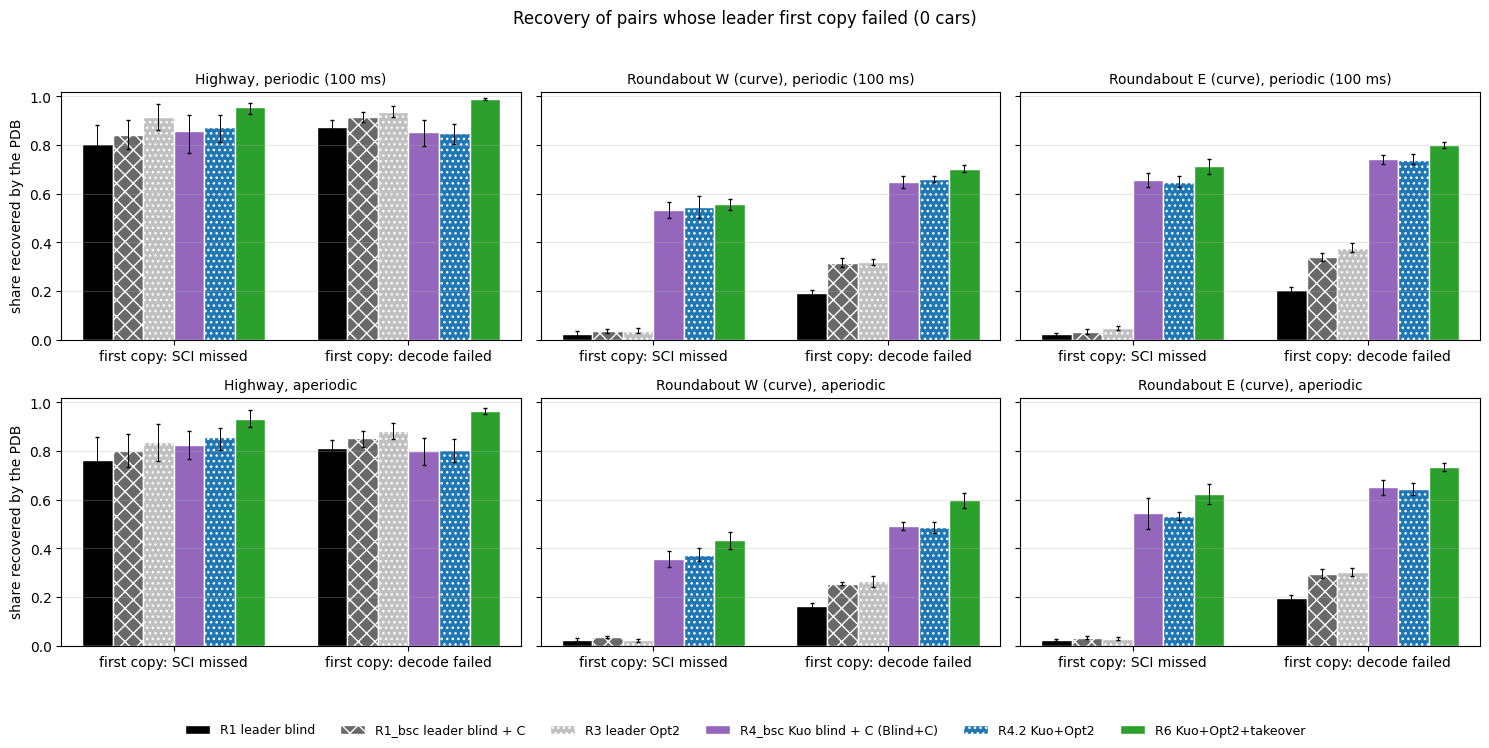

arm                                 R1  R1_bsc     R3  R4_bsc   R4.2     R6
sc   tr           first                                                    
hwy  aperiodic1tb SCI missed     0.765   0.801  0.836   0.823  0.857  0.934
                  decode failed  0.811   0.852  0.884   0.802  0.806  0.964
     periodic1tb  SCI missed     0.804   0.841  0.916   0.858  0.874  0.955
                  decode failed  0.875   0.915  0.938   0.856  0.851  0.988
rbt  aperiodic1tb SCI missed     0.025   0.036  0.022   0.357  0.374  0.432
                  decode failed  0.164   0.254  0.264   0.490  0.486  0.597
     periodic1tb  SCI missed     0.025   0.034  0.036   0.534  0.547  0.556
                  decode failed  0.190   0.316  0.319   0.648  0.660  0.703
rbtE aperiodic1tb SCI missed     0.023   0.033  0.028   0.544  0.533  0.623
                  decode failed  0.195   0.296  0.303   0.650  0.644  0.734
     periodic1tb  SCI missed     0.021   0.032  0.048   0.656  0.649  0.714
                  decode failed  0.206   0.341  0.377   0.742  0.739  0.800

In [5]:
rows = []
for (sc, tr, arm, st1), g in CAT[CAT.st1.isin([0, 2])].groupby(['sc', 'tr', 'arm', 'st1']):
    g = g.assign(d=np.where(g.src != 'lost', g.n, 0))
    r, lo, hi, n = A.boot_ratio(g, 'd', 'n')
    rows.append(dict(sc=sc, tr=tr, arm=arm, first='SCI missed' if st1 == 0 else 'decode failed', rec=r, lo=lo, hi=hi,
                     pairs=int(g.n.sum()), n_seeds=n))
REC = pd.DataFrame(rows); REC.to_csv(F('tab_recovery_after_first_fail.csv'), index=False)
fs = CAT[(CAT.st1 >= 0)].groupby(['sc', 'tr', 'st1']).n.sum().unstack('st1')
display(Markdown('First-copy outcome, share of pairs (%), all arms pooled (0 = SCI missed, 1 = decoded, 2 = decode failed)'))
display((fs.div(fs.sum(1), axis=0) * 100).round(1))
fig, ax = plt.subplots(2, 3, figsize=(15, 7.5), sharey=True)
w = .13
for i, tr in enumerate(A.TRS):
    for j, sc in enumerate(A.SCS):
        a = ax[i, j]
        for k, arm in enumerate(ARMS):
            g = REC[(REC.sc == sc) & (REC.tr == tr) & (REC.arm == arm)].set_index('first').reindex(['SCI missed', 'decode failed'])
            x = np.arange(2) + (k - (len(ARMS) - 1) / 2) * w
            a.bar(x, g.rec, w, yerr=[g.rec - g.lo, g.hi - g.rec], color=A.STYLE[arm][0], capsize=1.5, error_kw=dict(lw=.7),
                  edgecolor='white', hatch={'-': '', '--': '///', ':': '...', '-.': 'xx'}[A.STYLE[arm][1]])
        a.set_xticks([0, 1]); a.set_xticklabels(['first copy: SCI missed', 'first copy: decode failed'])
        a.set_title(f'{A.SCN[sc]}, {A.TRN[tr]}', fontsize=10); a.set_ylim(0, 1.02); a.grid(axis='y', alpha=.3)
        if j == 0: a.set_ylabel('share recovered by the PDB')
fig.suptitle('Recovery of pairs whose leader first copy failed (0 cars)', fontsize=12)
A.finish(fig, [Patch(facecolor=A.STYLE[a][0], hatch={'-': '', '--': '///', ':': '...', '-.': 'xx'}[A.STYLE[a][1]],
                     edgecolor='white', label=A.LABEL[a]) for a in ARMS], F('fig3_recovery_after_first_fail'), ncol=6)
plt.show()
display(REC.pivot_table(index=['sc', 'tr', 'first'], columns='arm', values='rec')[ARMS].round(3))


## 4. PRR per member position
Member 1 follows the leader, member 8 is the tail. Shows where in the platoon each scheme gains.

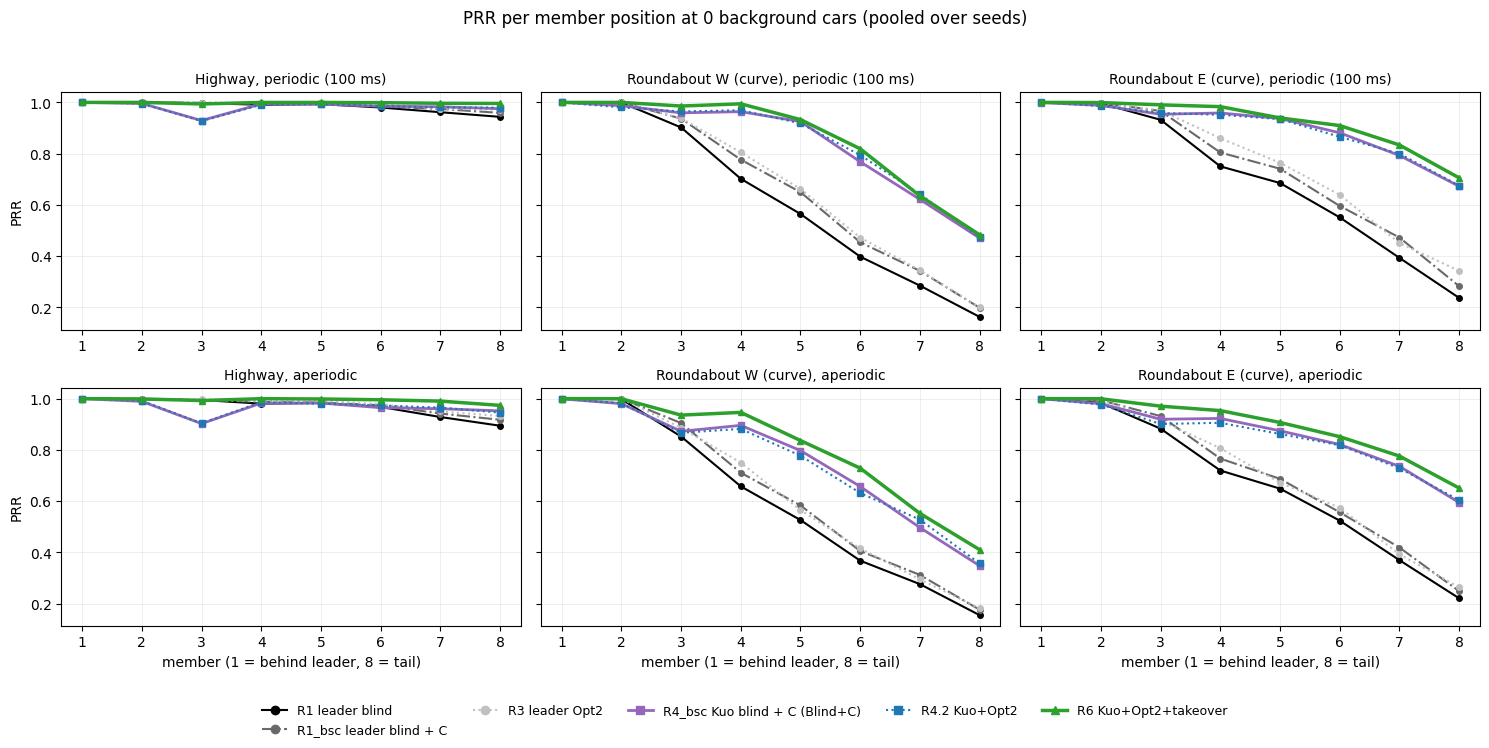

arm                          R1  R1_bsc     R3  R4_bsc   R4.2     R6
sc   tr           member                                            
hwy  aperiodic1tb 1       1.000   1.000  1.000   1.000  1.000  1.000
                  2       0.998   0.999  0.999   0.989  0.991  0.999
                  3       0.995   0.995  0.997   0.902  0.904  0.993
                  4       0.980   0.987  0.990   0.983  0.986  1.000
                  5       0.983   0.985  0.991   0.983  0.980  0.999
                  6       0.968   0.974  0.979   0.965  0.973  0.996
                  7       0.928   0.942  0.950   0.961  0.965  0.990
                  8       0.894   0.918  0.932   0.952  0.946  0.974
     periodic1tb  1       1.000   1.000  1.000   1.000  1.000  1.000
                  2       0.999   1.000  1.000   0.996  0.996  1.000
                  3       0.997   0.999  1.000   0.929  0.927  0.994
                  4       0.991   0.995  0.997   0.994  0.991  1.000
                  5       0.994   0.996  0.998   0.993  0.993  1.000
                  6       0.980   0.984  0.992   0.985  0.986  0.999
                  7       0.962   0.974  0.976   0.983  0.981  0.997
                  8       0.944   0.959  0.972   0.975  0.979  0.996
rbt  aperiodic1tb 1       1.000   1.000  1.000   0.999  0.999  1.000
                  2       0.998   1.000  1.000   0.980  0.982  1.000
                  3       0.852   0.905  0.886   0.873  0.867  0.936
                  4       0.658   0.711  0.750   0.896  0.882  0.946
                  5       0.526   0.583  0.565   0.797  0.777  0.837
                  6       0.368   0.406  0.416   0.657  0.632  0.729
                  7       0.276   0.312  0.295   0.497  0.528  0.552
                  8       0.155   0.177  0.182   0.348  0.357  0.411
     periodic1tb  1       1.000   1.000  1.000   1.000  1.000  1.000
                  2       1.000   1.000  1.000   0.987  0.981  1.000
                  3       0.902   0.937  0.938   0.959  0.965  0.986
                  4       0.702   0.777  0.805   0.964  0.969  0.995
                  5       0.565   0.650  0.662   0.925  0.918  0.933
                  6       0.398   0.454  0.473   0.768  0.794  0.819
                  7       0.285   0.343  0.345   0.622  0.642  0.635
                  8       0.163   0.199  0.200   0.471  0.475  0.484
rbtE aperiodic1tb 1       1.000   1.000  1.000   1.000  0.999  1.000
                  2       0.983   0.993  0.996   0.980  0.977  0.999
                  3       0.883   0.932  0.915   0.920  0.901  0.971
                  4       0.720   0.766  0.807   0.923  0.906  0.953
                  5       0.649   0.687  0.672   0.875  0.862  0.907
                  6       0.524   0.557  0.575   0.821  0.818  0.852
                  7       0.370   0.419  0.393   0.736  0.728  0.776
                  8       0.221   0.249  0.264   0.595  0.604  0.651
     periodic1tb  1       1.000   1.000  1.000   0.999  1.000  1.000
                  2       0.996   0.998  0.997   0.988  0.986  0.999
                  3       0.932   0.966  0.969   0.954  0.959  0.990
                  4       0.750   0.805  0.860   0.959  0.952  0.983
                  5       0.685   0.741  0.765   0.937  0.935  0.939
                  6       0.551   0.596  0.639   0.881  0.866  0.910
                  7       0.394   0.473  0.452   0.793  0.800  0.834
                  8       0.237   0.283  0.343   0.673  0.675  0.706

In [6]:
PM = CAT.assign(d=np.where(CAT.src != 'lost', CAT.n, 0)).groupby(['sc', 'tr', 'arm', 'member'])[['d', 'n']].sum()
PM['prr'] = PM.d / PM.n; PM = PM.reset_index(); PM.to_csv(F('tab_prr_per_member.csv'), index=False)
fig, ax = A.grid('PRR per member position at 0 background cars (pooled over seeds)', 'PRR', 'member (1 = behind leader, 8 = tail)')
for i, tr in enumerate(A.TRS):
    for j, sc in enumerate(A.SCS):
        for arm in ARMS:
            g = PM[(PM.sc == sc) & (PM.tr == tr) & (PM.arm == arm)]
            col, ls, lw = A.STYLE[arm]; ax[i, j].plot(g.member, g.prr, ls=ls, color=col, lw=lw, marker=A.MARK[arm], ms=4)
        ax[i, j].set_xticks(range(1, 9))
A.finish(fig, A.arm_handles(ARMS), F('fig4_prr_per_member')); plt.show()
display(PM.pivot_table(index=['sc', 'tr', 'member'], columns='arm', values='prr')[ARMS].round(3))


## 5. Helper reception of the first copy and its influence on PRR
**Helper reception probability** = share of TBs whose selected helper (Kuo, chosen per TB) decoded the leader's first
transmission, i.e. could relay in its first handed slot. Leader-only arms have no helper.

In [7]:
rows = []
for (sc, tr, arm), g in WIN[WIN.arm.isin(['R4_bsc', 'R4.2', 'R6'])].groupby(['sc', 'tr', 'arm']):
    r, lo, hi, n = A.boot_ratio(g, 'n_helper_ok', 'n_helper')
    rows.append(dict(sc=sc, tr=tr, arm=arm, helper_reception=r, lo=lo, hi=hi, tbs=int(g.n_helper.sum()), n_seeds=n))
HR = pd.DataFrame(rows); HR.to_csv(F('tab_helper_reception.csv'), index=False)
display(HR.pivot_table(index=['sc', 'tr'], columns='arm', values=['helper_reception', 'lo', 'hi']).round(3))


helper_reception                   hi                   lo              
arm                           R4.2 R4_bsc     R6   R4.2 R4_bsc     R6   R4.2 R4_bsc     R6
sc   tr                                                                                   
hwy  aperiodic1tb            0.901  0.899  0.903  0.927  0.929  0.928  0.870  0.862  0.872
     periodic1tb             0.927  0.929  0.929  0.948  0.956  0.953  0.900  0.895  0.901
rbt  aperiodic1tb            0.853  0.858  0.856  0.869  0.871  0.877  0.833  0.842  0.835
     periodic1tb             0.947  0.948  0.940  0.957  0.959  0.956  0.938  0.937  0.924
rbtE aperiodic1tb            0.890  0.909  0.902  0.904  0.922  0.912  0.877  0.897  0.891
     periodic1tb             0.950  0.948  0.951  0.961  0.958  0.963  0.937  0.936  0.941

**Per TB (descriptive):** PRR of the TBs whose helper received the first copy vs those whose helper did not,
over the **other seven members** (the helper's own reception is the condition, so it is left out) and over all
eight. The two groups of TBs differ in more than the helper (a TB whose helper failed often has a bad channel for
its neighbours too), so the gap is an association, not the effect of the helper alone.

In [8]:
rows = []
for (sc, tr, arm), g in CAT[(CAT.helper_ok >= 0) & CAT.arm.isin(['R4_bsc', 'R4.2', 'R6'])].groupby(['sc', 'tr', 'arm']):
    g = g.assign(d=np.where(g.src != 'lost', g.n, 0))
    row = dict(sc=sc, tr=tr, arm=arm)
    for ok, nm in ((1, 'helper_rx'), (0, 'helper_missed')):
        for scope, gg in (('others', g[(g.helper_ok == ok) & (g.is_helper == 0)]), ('all8', g[g.helper_ok == ok])):
            r, lo, hi, n = A.boot_ratio(gg, 'd', 'n')
            row |= {f'{nm}_{scope}': r, f'{nm}_{scope}_lo': lo, f'{nm}_{scope}_hi': hi}
        row[f'pairs_{nm}'] = int(g[g.helper_ok == ok].n.sum())
    rows.append(row)
CH = pd.DataFrame(rows); CH.to_csv(F('tab_prr_given_helper_reception.csv'), index=False)
display(CH.set_index(['sc', 'tr', 'arm'])[['pairs_helper_rx', 'helper_rx_others', 'pairs_helper_missed', 'helper_missed_others',
                                          'helper_missed_others_lo', 'helper_missed_others_hi', 'helper_rx_all8',
                                          'helper_missed_all8']].round(3))


pairs_helper_rx  helper_rx_others  pairs_helper_missed  helper_missed_others  helper_missed_others_lo  helper_missed_others_hi  helper_rx_all8  helper_missed_all8
sc   tr           arm                                                                                                                                                                       
hwy  aperiodic1tb R4.2              35864             0.995                 3928                 0.817                    0.786                    0.842           0.996               0.715
                  R4_bsc            35768             0.996                 4024                 0.801                    0.782                    0.818           0.997               0.701
                  R6                35936             0.996                 3856                 0.978                    0.964                    0.988           0.996               0.969
     periodic1tb  R4.2              36840             0.999                 2920                 0.875                    0.851                    0.899           0.999               0.766
                  R4_bsc            36920             0.998                 2840                 0.874                    0.857                    0.890           0.999               0.765
                  R6                36952             0.999                 2808                 0.993                    0.990                    0.996           0.999               0.984
rbt  aperiodic1tb R4.2              17400             0.805                 3008                 0.359                    0.345                    0.370           0.829               0.314
                  R4_bsc            17504             0.804                 2904                 0.366                    0.351                    0.381           0.828               0.321
                  R6                17464             0.810                 2944                 0.618                    0.578                    0.659           0.834               0.609
     periodic1tb  R4.2              19312             0.850                 1072                 0.433                    0.405                    0.457           0.869               0.379
                  R4_bsc            19320             0.844                 1064                 0.405                    0.375                    0.435           0.864               0.354
                  R6                19168             0.844                 1216                 0.741                    0.692                    0.792           0.864               0.743
rbtE aperiodic1tb R4.2              25440             0.891                 3136                 0.461                    0.433                    0.489           0.905               0.403
                  R4_bsc            25976             0.884                 2600                 0.491                    0.457                    0.534           0.899               0.429
                  R6                25768             0.894                 2808                 0.719                    0.681                    0.759           0.907               0.717
     periodic1tb  R4.2              27096             0.909                 1440                 0.519                    0.476                    0.571           0.920               0.454
                  R4_bsc            27040             0.911                 1496                 0.536                    0.495                    0.585           0.922               0.469
                  R6                27136             0.915                 1400                 0.824                    0.778                    0.865           0.925               0.819

**PRR versus helper reception probability (descriptive association).** Each run is cut into 2 s windows
(by packet generation time); x = share of TBs in the window whose helper received the first copy, windows binned,
each point at the TB-weighted mean x of its bin; y = PRR of the pairs in those windows. Cooperative arms use their
own helper; the leader-only references (hollow) are placed at R6's helper reception in the same window (same trace
and seed), showing what the leader alone achieves in the same conditions. Top figure: all 8 members (the PRR you
measure); bottom figure: the 7 non-helper members only (removes the mechanical part: the helper's own reception is
x). The helper reception varies along the trace with the geometry, so x also tracks how hard the channel is for
everyone: this is not the effect of the helper reception alone. Points need ≥ 5 seeds and ≥ 200 pairs; counts in the
CSV.

/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_79926/3792520023.py:24: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sup = p.supported.fillna(False).astype(bool).values
/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_79926/3792520023.py:24: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sup = p.supported.fillna(False).astype(bool).values
/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_79926/3792520023.py:24: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future

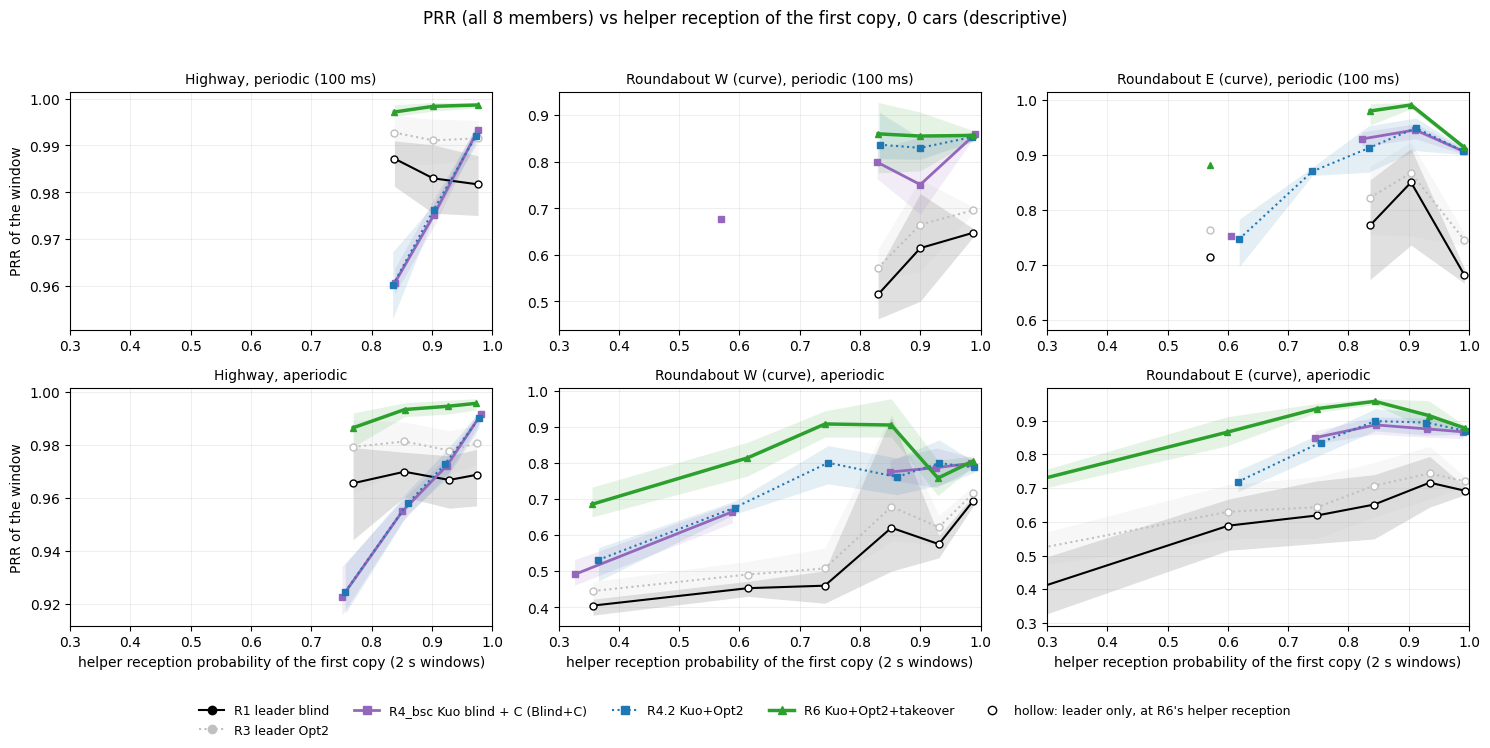

166 points, 38 unsupported (not drawn).

/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_79926/3792520023.py:24: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sup = p.supported.fillna(False).astype(bool).values
/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_79926/3792520023.py:24: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sup = p.supported.fillna(False).astype(bool).values
/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_79926/3792520023.py:24: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future

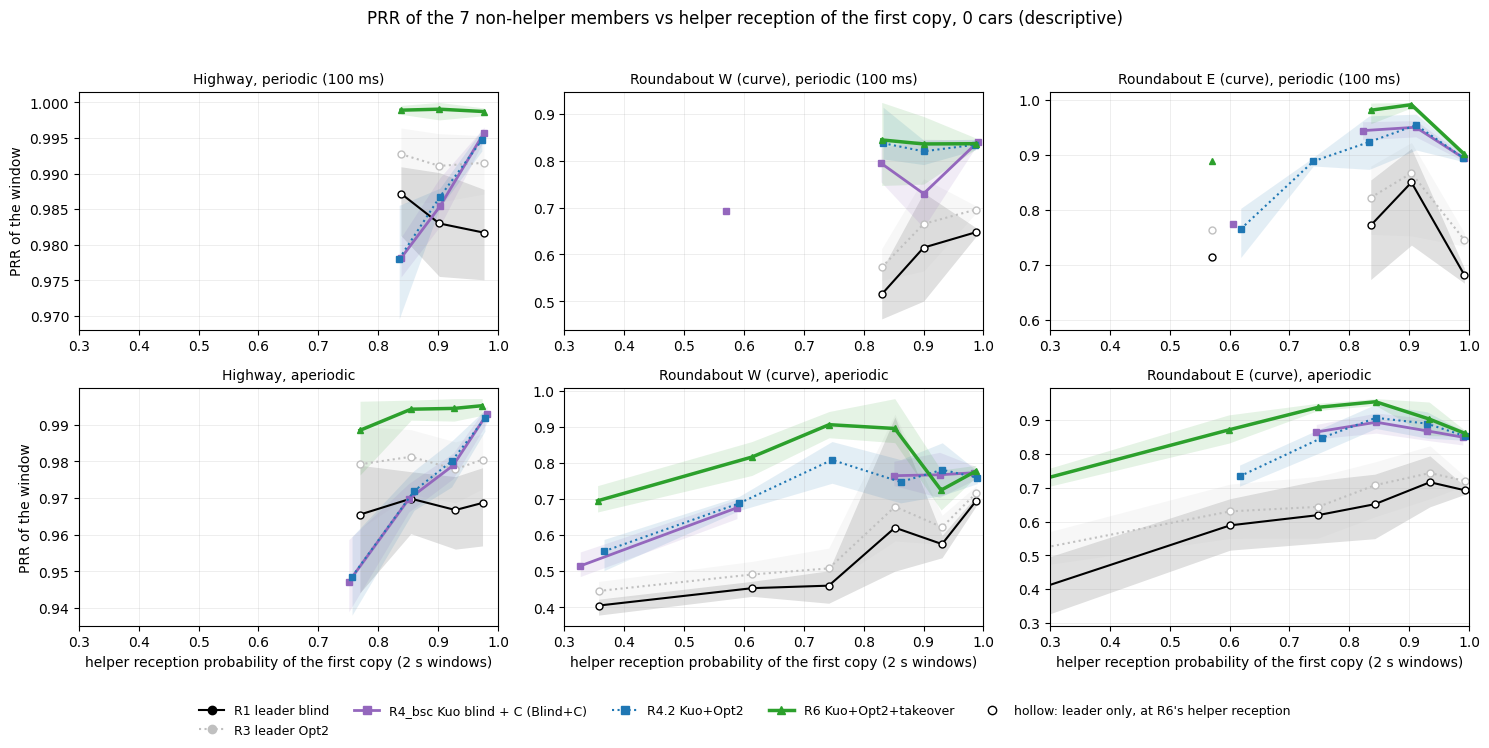

166 points, 38 unsupported (not drawn).

In [9]:
HR_EDGES = [0, .5, .7, .8, .9, .95, 1.0001]
ref = WIN[WIN.arm == 'R6'].set_index(['sc', 'tr', 'seed', 'w'])[['n_helper_ok', 'n_helper']]
xs = []
for arm in ['R1', 'R3', 'R4_bsc', 'R4.2', 'R6']:
    x = WIN[WIN.arm == arm].copy()
    if arm in ('R4_bsc', 'R4.2', 'R6'):
        x['hf'] = x.n_helper_ok / x.n_helper.replace(0, np.nan)
    else:
        r = ref.reindex(pd.MultiIndex.from_frame(x[['sc', 'tr', 'seed', 'w']]))
        x['hf'] = (r.n_helper_ok / r.n_helper.replace(0, np.nan)).values
    xs.append(x.dropna(subset=['hf']))
XW = pd.concat(xs); XW['hbin'] = pd.cut(XW.hf, HR_EDGES, right=False, labels=False)
HB = list(range(len(HR_EDGES) - 1))
def helper_curve(num, den, name, title):
    P = A.binned_points(XW, ['sc', 'tr', 'arm'], num, den, A.MIN_PAIRS, count_cols=('n_pairs', 'n_helper'))
    P.to_csv(F(name + '_points.csv'), index=False)
    fig, ax = A.grid(title, 'PRR of the window', 'helper reception probability of the first copy (2 s windows)', sharey=False)
    for i, tr in enumerate(A.TRS):
        for j, sc in enumerate(A.SCS):
            a = ax[i, j]
            for arm in ['R1', 'R3', 'R4_bsc', 'R4.2', 'R6']:
                p = A.full_bins(P[(P.sc == sc) & (P.tr == tr) & (P.arm == arm)], 'hbin', HB)
                col, ls, lw = A.STYLE[arm]
                sup = p.supported.fillna(False).astype(bool).values
                y = np.where(sup, p.y, np.nan)
                for seg in A.segments(p.x.values, y):
                    xx, yy = zip(*seg); a.plot(xx, yy, ls=ls, color=col, lw=lw, marker=A.MARK[arm], ms=5,
                                               mfc='white' if arm in ('R1', 'R3') else col)
                A.band(a, p.x.values, p.lo.values, p.hi.values, sup, col)
            a.set_xlim(.3, 1.0)
    A.finish(fig, A.arm_handles(['R1', 'R3', 'R4_bsc', 'R4.2', 'R6']) +
             [Line2D([], [], color='k', marker='o', mfc='white', ls='', label="hollow: leader only, at R6's helper reception")],
             F(name))
    plt.show()
    un = P[~P.supported]
    display(Markdown(f'{len(P)} points, {len(un)} unsupported (not drawn).'))
    return P
P5a = helper_curve('n_deliv', 'n_pairs', 'fig5a_prr_vs_helper_reception_all8',
                   'PRR (all 8 members) vs helper reception of the first copy, 0 cars (descriptive)')
P5b = helper_curve('n_deliv_nh', 'n_pairs_nh', 'fig5b_prr_vs_helper_reception_others',
                   'PRR of the 7 non-helper members vs helper reception of the first copy, 0 cars (descriptive)')


**Distribution of the helper reception** over the windows (R6): how much of the time each bin covers, so the
curves are read with their weight.

In [10]:
x = XW[XW.arm == 'R6']
t = x.groupby(['sc', 'tr', 'hbin']).n_pkt.sum().unstack('hbin').fillna(0)
t.columns = [f'[{HR_EDGES[int(c)]:.2f}, {min(HR_EDGES[int(c) + 1], 1):.2f})' for c in t.columns]
display((t.div(t.sum(1), axis=0) * 100).round(1))


[0.00, 0.50)  [0.50, 0.70)  [0.70, 0.80)  [0.80, 0.90)  [0.90, 0.95)  [0.95, 1.00)
sc   tr                                                                                              
hwy  aperiodic1tb           0.0           3.0           7.9          27.6          25.1          36.5
     periodic1tb            0.0           0.0           5.2          13.2          21.1          60.5
rbt  aperiodic1tb           9.5          10.7           6.2           6.4          12.7          54.4
     periodic1tb            2.4           2.4           1.9           3.9           9.4          80.1
rbtE aperiodic1tb           3.0           8.1           6.9          10.1          10.9          61.1
     periodic1tb            1.7           2.8           2.8           5.5           4.4          82.9

## 5b. Where the takeover acts: TBs whose helper received vs missed the first copy
Every pair of the cooperative arms is put in one of two groups by **its own arm's** helper outcome for that TB:
*received* (the TB's helper decoded the leader's first copy) or *missed*. The groups are not the same TBs in every
arm (the helper of a TB can succeed in one arm and fail in another by chance), but they are of similar size (5–15 %
of pairs missed), and every quantity below adds up exactly to the arm totals of sections 1–2.

**(a) Delivering copy by group**, in % of **all** pairs of the arm. In the received group the three arms should and
do behave the same (R6 never takes over there); everything that separates them sits in the missed group.

**Helper received**: % of all pairs

src                          L1      H   T1   T2   LH   lost
sc   tr           arm                                       
hwy  aperiodic1tb R4.2    76.28  13.48  0.0  0.0  0.0   0.37
                  R4_bsc  76.07  13.53  0.0  0.0  0.0   0.30
                  R6      76.55  13.42  0.0  0.0  0.0   0.34
     periodic1tb  R4.2    81.90  10.64  0.0  0.0  0.0   0.12
                  R4_bsc  81.99  10.74  0.0  0.0  0.0   0.13
                  R6      82.11  10.75  0.0  0.0  0.0   0.07
rbt  aperiodic1tb R4.2    49.67  21.01  0.0  0.0  0.0  14.58
                  R4_bsc  50.27  20.77  0.0  0.0  0.0  14.73
                  R6      50.28  21.05  0.0  0.0  0.0  14.24
     periodic1tb  R4.2    55.26  27.05  0.0  0.0  0.0  12.43
                  R4_bsc  55.05  26.81  0.0  0.0  0.0  12.92
                  R6      54.56  26.64  0.0  0.0  0.0  12.83
rbtE aperiodic1tb R4.2    56.00  24.53  0.0  0.0  0.0   8.50
                  R4_bsc  57.27  24.43  0.0  0.0  0.0   9.20
                  R6      57.54  24.28  0.0  0.0  0.0   8.35
     periodic1tb  R4.2    60.91  26.45  0.0  0.0  0.0   7.59
                  R4_bsc  60.77  26.58  0.0  0.0  0.0   7.41
                  R6      61.27  26.74  0.0  0.0  0.0   7.09

**Helper missed**: % of all pairs

src                         L1     H    T1    T2   LH   lost
sc   tr           arm                                       
hwy  aperiodic1tb R4.2    7.06  0.00  0.00  0.00  0.0   2.81
                  R4_bsc  7.09  0.00  0.00  0.00  0.0   3.02
                  R6      6.73  0.27  2.11  0.28  0.0   0.30
     periodic1tb  R4.2    5.62  0.00  0.00  0.00  0.0   1.72
                  R4_bsc  5.46  0.00  0.00  0.00  0.0   1.68
                  R6      5.41  0.10  1.20  0.24  0.0   0.12
rbt  aperiodic1tb R4.2    4.63  0.00  0.00  0.00  0.0  10.11
                  R4_bsc  4.56  0.00  0.00  0.00  0.0   9.67
                  R6      4.49  2.32  1.88  0.10  0.0   5.64
     periodic1tb  R4.2    1.99  0.00  0.00  0.00  0.0   3.27
                  R4_bsc  1.85  0.00  0.00  0.00  0.0   3.37
                  R6      2.26  1.01  1.11  0.06  0.0   1.53
rbtE aperiodic1tb R4.2    4.43  0.00  0.00  0.00  0.0   6.55
                  R4_bsc  3.91  0.00  0.00  0.00  0.0   5.19
                  R6      3.73  1.67  1.60  0.05  0.0   2.78
     periodic1tb  R4.2    2.29  0.00  0.00  0.00  0.0   2.75
                  R4_bsc  2.46  0.00  0.00  0.00  0.0   2.78
                  R6      2.12  0.83  1.04  0.02  0.0   0.89

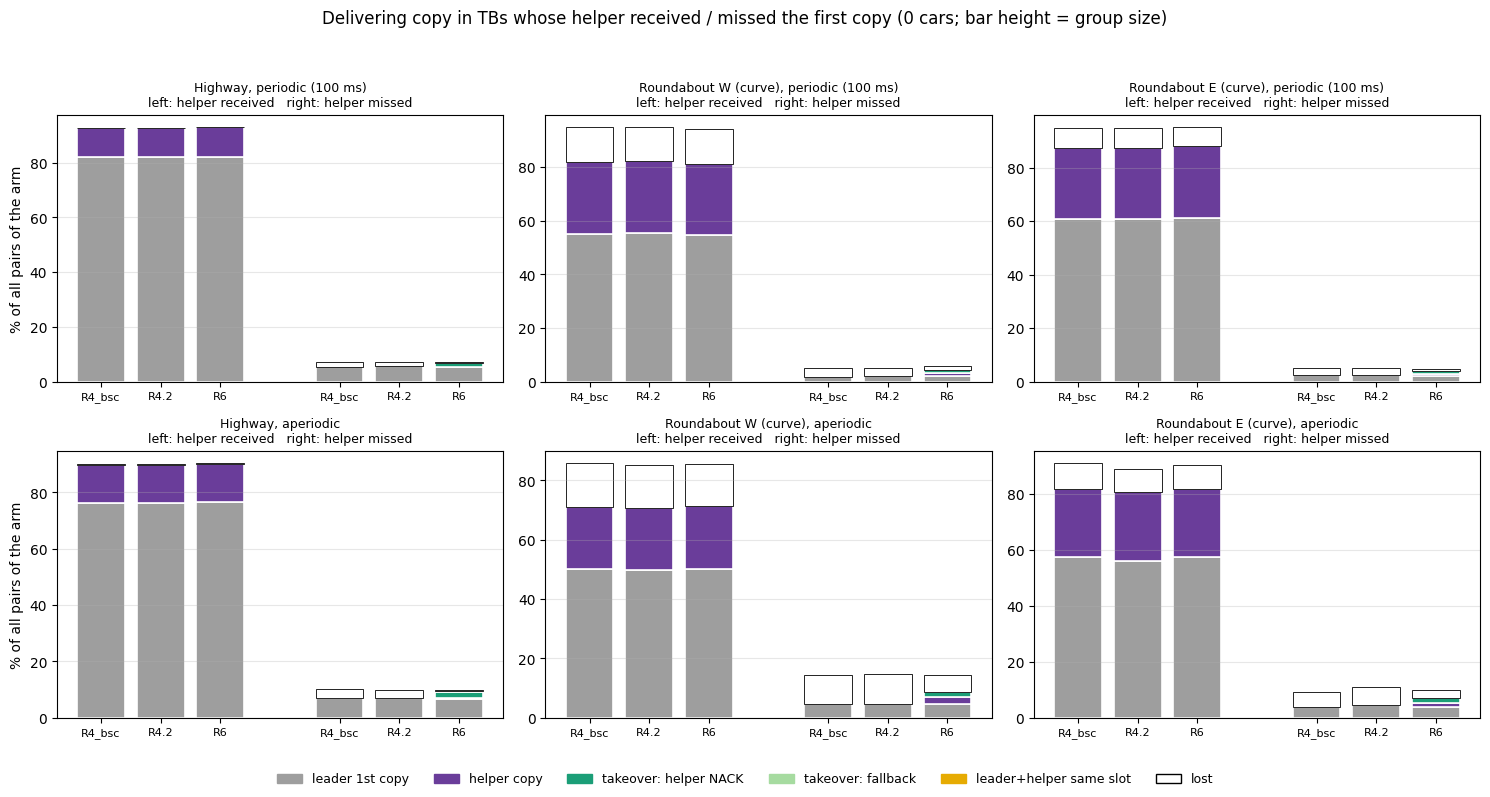

In [11]:
COOP = ['R4_bsc', 'R4.2', 'R6']
CC = CAT[CAT.arm.isin(COOP) & (CAT.helper_ok >= 0)]
TOT = CC.groupby(['sc', 'tr', 'arm']).n.sum()
G = CC.assign(group=np.where(CC.helper_ok == 1, 'received', 'missed'))
SG = G.groupby(['sc', 'tr', 'group', 'arm', 'src']).n.sum().unstack('src').reindex(columns=['L1', 'H', 'T1', 'T2', 'LH', 'lost'],
                                                                                  fill_value=0).fillna(0)
SG = SG.div(TOT.reindex(SG.index.droplevel('group')).values, axis=0) * 100
SG.to_csv(F('tab_5b_shares_by_helper_outcome.csv'))
for grp in ('received', 'missed'):
    display(Markdown(f'**Helper {grp}**: % of all pairs')); display(SG.xs(grp, level='group').round(2))

fig, ax = plt.subplots(2, 3, figsize=(15, 8), sharey=False)
show = ['L1', 'H', 'T1', 'T2', 'LH', 'lost']
for i, tr in enumerate(A.TRS):
    for j, sc in enumerate(A.SCS):
        a = ax[i, j]; xt, xl = [], []
        for gi, grp in enumerate(('received', 'missed')):
            for k, arm in enumerate(COOP):
                x = gi * (len(COOP) + 1) + k; bottom = 0.0
                v = SG.loc[(sc, tr, grp, arm)]
                for s in show:
                    a.bar(x, v[s], bottom=bottom, color=SRC_COL[s], edgecolor='k' if s == 'lost' else 'white',
                          lw=.6 if s == 'lost' else 1.2, width=.8)
                    bottom += v[s]
                xt.append(x); xl.append(arm)
        a.set_xticks(xt); a.set_xticklabels(xl, fontsize=8, rotation=0)
        a.set_title(f'{A.SCN[sc]}, {A.TRN[tr]}\nleft: helper received   right: helper missed', fontsize=9)
        a.grid(axis='y', alpha=.3)
        if j == 0: a.set_ylabel('% of all pairs of the arm')
fig.suptitle('Delivering copy in TBs whose helper received / missed the first copy (0 cars; bar height = group size)', fontsize=12)
fig.legend(handles=[Patch(facecolor=SRC_COL[s], edgecolor='k' if s == 'lost' else SRC_COL[s], label=SRC_NAME[s]) for s in show],
           loc='lower center', ncol=6, fontsize=9, frameon=False)
fig.tight_layout(rect=(0, .05, 1, .95)); fig.savefig(F('fig5b_shares_by_helper_outcome.pdf'), bbox_inches='tight')
fig.savefig(F('fig5b_shares_by_helper_outcome.png'), dpi=130, bbox_inches='tight'); plt.show()


**(b) Paired gain split by group.** Net PRR gain of R6 over R4.2 (takeover package) and over R4_bsc (Blind + C) =
part from the received group + part from the missed group, each = (delivered pairs of the group in R6 − in the
baseline) / all pairs, in pp. Same seed indices for both arms (paired bootstrap, 20 000 replicates); packets are
identical within the helper family, so the denominators are equal.

In [12]:
def group_split(p, b, sc, tr, B=A.B_PAIRED):
    def per_seed(arm):
        g = G[(G.arm == arm) & (G.sc == sc) & (G.tr == tr)]
        d = g[g.src != 'lost'].pivot_table(index='seed', columns='group', values='n', aggfunc='sum', fill_value=0)
        d = d.reindex(columns=['received', 'missed'], fill_value=0).reindex(range(1, 11), fill_value=0)
        n = g.groupby('seed').n.sum().reindex(range(1, 11), fill_value=0)
        return d.to_numpy(float), n.to_numpy(float)
    Dp, Np = per_seed(p); Db, Nb = per_seed(b)
    assert (Np == Nb).all(), 'pair counts differ inside the helper family'
    idx = rng.integers(0, len(Np), (B, len(Np)))
    bs = (Dp[idx].sum(1) - Db[idx].sum(1)) / Np[idx].sum(1)[:, None] * 100
    pt = (Dp.sum(0) - Db.sum(0)) / Np.sum() * 100
    lo, hi = np.percentile(bs, [2.5, 97.5], axis=0)
    net = bs.sum(1)
    return dict(from_received=pt[0], rec_lo=lo[0], rec_hi=hi[0], from_missed=pt[1], mis_lo=lo[1], mis_hi=hi[1],
                net=pt.sum(), net_lo=np.percentile(net, 2.5), net_hi=np.percentile(net, 97.5))
rows = [dict(comparison=f'R6 − {b}', sc=sc, tr=tr) | group_split('R6', b, sc, tr) for b in ('R4.2', 'R4_bsc') for sc, tr in CELLS]
GS = pd.DataFrame(rows); GS.to_csv(F('tab_5b_gain_by_helper_outcome.csv'), index=False)
display(GS.set_index(['comparison', 'sc', 'tr']).round(2))


from_received  rec_lo  rec_hi  from_missed  mis_lo  mis_hi   net  net_lo  net_hi
comparison  sc   tr                                                                                            
R6 − R4.2   hwy  periodic1tb            0.33   -0.94    1.68         1.32    0.01    2.56  1.65    1.22    2.19
            rbt  periodic1tb           -1.11   -2.46    0.41         2.44    1.66    3.24  1.33    0.58    2.21
            rbtE periodic1tb            0.64   -1.30    2.84         1.73    0.27    2.96  2.37    1.27    3.38
            hwy  aperiodic1tb           0.21   -0.99    1.38         2.34    1.06    3.55  2.55    1.88    3.32
            rbt  aperiodic1tb           0.66   -1.22    2.56         4.16    3.14    5.14  4.82    3.53    5.97
            rbtE aperiodic1tb           1.29   -0.49    3.03         2.62    1.70    3.57  3.91    3.00    4.84
R6 − R4_bsc hwy  periodic1tb            0.14   -0.70    0.98         1.48    0.77    2.14  1.62    1.01    2.32
            rbt  periodic1tb           -0.65   -2.34    1.05         2.59    1.36    3.71  1.93    1.14    2.72
            rbtE periodic1tb            0.66   -0.57    1.61         1.56    0.73    2.33  2.22    1.49    2.86
            hwy  aperiodic1tb           0.38   -1.20    1.87         2.30    1.07    3.53  2.69    1.80    3.70
            rbt  aperiodic1tb           0.30   -2.18    2.87         4.23    2.87    5.33  4.53    2.78    6.06
            rbtE aperiodic1tb           0.12   -1.88    1.96         3.14    2.22    4.03  3.26    1.92    4.50

**(c) How much of the recoverable loss the takeover gets.** Within the missed group: the PRR of each arm, the
received group's PRR as a reference (what a working helper achieves for comparable members), the loss the
baseline leaves in the missed group (`ceiling_pp`, % of all pairs: the most any fix inside that group could add),
the part R6 recovers over R4.2 (`recovered_pp`) and its share of the ceiling.

In [13]:
PG_ = G.assign(d=np.where(G.src != 'lost', G.n, 0)).groupby(['sc', 'tr', 'arm', 'group'])[['d', 'n']].sum()
PG_['prr'] = PG_.d / PG_.n
W5 = PG_.prr.unstack(['arm', 'group'])
CE = pd.DataFrame({'missed_pair_share_R6': PG_.xs(('R6', 'missed'), level=('arm', 'group')).n / TOT.xs('R6', level='arm'),
                   'prr_missed_R4_bsc': W5[('R4_bsc', 'missed')], 'prr_missed_R4.2': W5[('R4.2', 'missed')],
                   'prr_missed_R6': W5[('R6', 'missed')], 'prr_received_R6': W5[('R6', 'received')]})
lost_b = G[(G.arm == 'R4.2') & (G.group == 'missed') & (G.src == 'lost')].groupby(['sc', 'tr']).n.sum()
CE['ceiling_pp'] = 100 * lost_b / TOT.xs('R4.2', level='arm')
CE['recovered_pp'] = GS[GS.comparison == 'R6 − R4.2'].set_index(['sc', 'tr']).from_missed
CE['captured_pct'] = 100 * CE.recovered_pp / CE.ceiling_pp
CE.to_csv(F('tab_5b_takeover_ceiling.csv')); display(CE.round(3))


missed_pair_share_R6  prr_missed_R4_bsc  prr_missed_R4.2  prr_missed_R6  prr_received_R6  ceiling_pp  recovered_pp  captured_pct
sc   tr                                                                                                                                            
hwy  aperiodic1tb                 0.097              0.701            0.715          0.969            0.996       2.815         2.337        83.036
     periodic1tb                  0.071              0.765            0.766          0.984            0.999       1.720         1.323        76.901
rbt  aperiodic1tb                 0.144              0.321            0.314          0.609            0.834      10.109         4.160        41.154
     periodic1tb                  0.060              0.354            0.379          0.743            0.864       3.267         2.443        74.775
rbtE aperiodic1tb                 0.098              0.429            0.403          0.717            0.907       6.547         2.618        39.979
     periodic1tb                  0.049              0.469            0.454          0.819            0.925       2.754         1.728        62.723

**(d) Where R6 still loses.** Share of R6's lost pairs in TBs whose helper received / missed the first copy.
Losses in the received group cannot be addressed by a takeover (it never triggers there): those members are
reached neither by the leader nor by the chosen helper.

In [14]:
L6 = G[(G.arm == 'R6') & (G.src == 'lost')].groupby(['sc', 'tr', 'group']).n.sum().unstack('group')
L6 = L6.reindex(columns=['received', 'missed'], fill_value=0)
out = (L6.div(L6.sum(1), axis=0) * 100).rename(columns=lambda c: f'% of R6 losses, helper {c}')
out['R6 residual pair failure (%)'] = 100 * L6.sum(1) / TOT.xs('R6', level='arm')
out.to_csv(F('tab_5b_r6_losses_by_helper_outcome.csv')); display(out.round(1))


group              % of R6 losses, helper received  % of R6 losses, helper missed  R6 residual pair failure (%)
sc   tr                                                                                                        
hwy  aperiodic1tb                             53.2                           46.8                           0.6
     periodic1tb                              37.8                           62.2                           0.2
rbt  aperiodic1tb                             71.6                           28.4                          19.9
     periodic1tb                              89.3                           10.7                          14.4
rbtE aperiodic1tb                             75.0                           25.0                          11.1
     periodic1tb                              88.9                           11.1                           8.0

## 6. Cost at 0 cars
Transmissions per TB by kind, transmitted subchannel-slots per TB (PSSCH; PSFCH excluded) and the share of copies
sent after all 8 members already had the TB (redundant). Efficiency = delivered pairs / 8 per transmitted
subchannel-slot.

In [15]:
g = RUN.groupby(['sc', 'tr', 'arm']).sum(numeric_only=True)
K = ['L1', 'Lrep', 'H', 'T1', 'T2']
COST = pd.DataFrame({f'tx_{k}_per_tb': g[f'tx_{k}'] / g.n_pkt for k in K})
COST['tx_per_tb'] = sum(g[f'tx_{k}'] for k in K) / g.n_pkt
COST['ss_tx_per_tb'] = g.ss_tx / g.n_pkt
COST['redundant_pct'] = 100 * sum(g[f'red_{k}'] for k in K) / sum(g[f'tx_{k}'] for k in K)
dl = CAT.assign(d=np.where(CAT.src != 'lost', CAT.n, 0)).groupby(['sc', 'tr', 'arm']).d.sum()
COST['eff_tx'] = dl / 8 / g.ss_tx
COST = COST.reset_index(); COST = COST[COST.arm.isin(ARMS)]; COST.to_csv(F('tab_cost.csv'), index=False)
display(COST.set_index(['sc', 'tr', 'arm']).round(3))


tx_L1_per_tb  tx_Lrep_per_tb  tx_H_per_tb  tx_T1_per_tb  tx_T2_per_tb  tx_per_tb  ss_tx_per_tb  redundant_pct  eff_tx
sc   tr           arm                                                                                                                          
hwy  aperiodic1tb R1               1.0           2.000        0.000         0.000         0.000      3.000         9.382         27.989   0.103
                  R1_bsc           1.0           2.000        0.000         0.000         0.000      3.000         9.382         30.614   0.104
                  R3               1.0           1.116        0.000         0.000         0.000      2.116         7.012          2.094   0.140
                  R4.2             1.0           0.000        1.037         0.000         0.000      2.037         6.453         13.727   0.150
                  R4_bsc           1.0           0.000        1.798         0.000         0.000      2.798         8.760         37.899   0.110
                  R6               1.0           0.000        0.810         0.089         0.012      1.912         6.354          1.798   0.156
     periodic1tb  R1               1.0           2.000        0.000         0.000         0.000      3.000         5.913         34.393   0.166
                  R1_bsc           1.0           2.000        0.000         0.000         0.000      3.000         5.913         36.955   0.167
                  R3               1.0           0.908        0.000         0.000         0.000      1.908         3.764          2.109   0.263
                  R4.2             1.0           0.000        1.011         0.000         0.000      2.011         3.954         18.015   0.248
                  R4_bsc           1.0           0.000        1.857         0.000         0.000      2.857         5.615         42.394   0.175
                  R6               1.0           0.000        0.679         0.061         0.011      1.751         3.451          1.781   0.289
rbt  aperiodic1tb R1               1.0           2.000        0.000         0.000         0.000      3.000         9.381          5.284   0.064
                  R1_bsc           1.0           2.000        0.000         0.000         0.000      3.000         9.381          5.744   0.068
                  R3               1.0           1.825        0.000         0.000         0.000      2.825         8.862          0.084   0.072
                  R4.2             1.0           0.000        1.445         0.000         0.000      2.445         7.580          2.678   0.099
                  R4_bsc           1.0           0.000        1.715         0.000         0.000      2.715         8.336         10.871   0.091
                  R6               1.0           0.000        1.458         0.186         0.014      2.659         8.477          0.059   0.095
     periodic1tb  R1               1.0           2.000        0.000         0.000         0.000      3.000         5.913          5.992   0.106
                  R1_bsc           1.0           2.000        0.000         0.000         0.000      3.000         5.913          6.436   0.113
                  R3               1.0           1.810        0.000         0.000         0.000      2.810         5.544          0.070   0.122
                  R4.2             1.0           0.000        1.572         0.000         0.000      2.572         5.047          3.037   0.167
                  R4_bsc           1.0           0.000        1.896         0.000         0.000      2.896         5.679         13.554   0.147
                  R6               1.0           0.000        1.544         0.066         0.006      2.616         5.135          0.105   0.167
rbtE aperiodic1tb R1               1.0           2.000        0.000         0.000         0.000      3.000         9.385          6.749   0.071
                  R1_bsc           1.0           2.000        0.000         0.000         0.000      3.000         9.385          7.609   